In [1]:
##### Figure 2: grid-scale capital and labor, including AOA analysis

from pathlib import Path
import string
import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
from matplotlib.patches import Rectangle
import rioxarray as rio

In [2]:
##### LOAD DATA

ROOT = Path.cwd().parent

# modeled capital and labor
capital_modeled = rio.open_rasterio(ROOT / "Results/Raster_models/rescaled_capital_USD.tif")
labor_modeled = rio.open_rasterio(ROOT / "Results/Raster_models/rescaled_jobs.tif")

# DI and AOA rasters (from AOA analysis notebook)
AOA_DIR = ROOT / "Results" / "AOA"
di_grid_capital = rio.open_rasterio(AOA_DIR / "DI_capital.tif", masked=True)
di_grid_labor = rio.open_rasterio(AOA_DIR / "DI_labor.tif", masked=True)
aoa_grid_capital = rio.open_rasterio(AOA_DIR / "AOA_capital.tif", masked=True)
aoa_grid_labor = rio.open_rasterio(AOA_DIR / "AOA_labor.tif", masked=True)

# production (used to shade AOA panels)
ref_path = ROOT / "Data" / "total_production_tonnes_2020.tif"

# country boundaries: simplified for mapping; download from https://www.geoboundaries.org/simplifiedDownloads.html
country_boundaries = gpd.read_file(ROOT / "Data/country_geo.shp")
has_data = pd.read_csv(ROOT / "Data/has_data.csv")

# figure output directory
FIG_DIR = ROOT / "Figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

In [3]:
##### Identify no data countries
country_boundaries = country_boundaries.merge(has_data, on="SHP_code", how="left")
country_boundaries["has_capital_data"] = country_boundaries["has_capital_data"].fillna(0)
country_boundaries["has_labor_data"] = country_boundaries["has_labor_data"].fillna(0)

##### Align data for plotting

crs = "+proj=eck4 +lon_0=0 +x_0=0 +y_0=0 +datum=WGS84 +units=m +no_defs"
country_boundaries = country_boundaries.to_crs(crs)
no_data_color = "#e0e0e0"

di_grid_labor = di_grid_labor.rio.reproject(crs)
di_grid_capital = di_grid_capital.rio.reproject(crs)
di_grid_capital = di_grid_capital.where(di_grid_capital > 0)
di_grid_labor = di_grid_labor.where(di_grid_labor > 0)

aoa_grid_labor = aoa_grid_labor.rio.reproject(crs).rio.reproject_match(di_grid_capital)
aoa_grid_capital = aoa_grid_capital.rio.reproject(crs).rio.reproject_match(di_grid_capital)
aoa_grid_capital = aoa_grid_capital.where(di_grid_capital.notnull())
aoa_grid_labor = aoa_grid_labor.where(di_grid_labor.notnull())

aoa_plot_capital = aoa_grid_capital.squeeze()
aoa_plot_labor = aoa_grid_labor.squeeze()

capital_modeled = capital_modeled.rio.reproject(crs).rio.reproject_match(di_grid_capital)
labor_modeled = labor_modeled.rio.reproject(crs).rio.reproject_match(di_grid_capital)
capital_modeled = capital_modeled.where(di_grid_capital.notnull()).squeeze()
labor_modeled = labor_modeled.where(di_grid_labor.notnull()).squeeze()

production_for_aoa = rio.open_rasterio(ref_path)
production_for_aoa = production_for_aoa.rio.reproject(crs).rio.reproject_match(di_grid_capital)
production_for_aoa = production_for_aoa.where(production_for_aoa > 0).squeeze()

prod_capital = production_for_aoa.where(aoa_plot_capital.notnull())
prod_labor = production_for_aoa.where(aoa_plot_labor.notnull())

minx, miny, maxx, maxy = country_boundaries.total_bounds

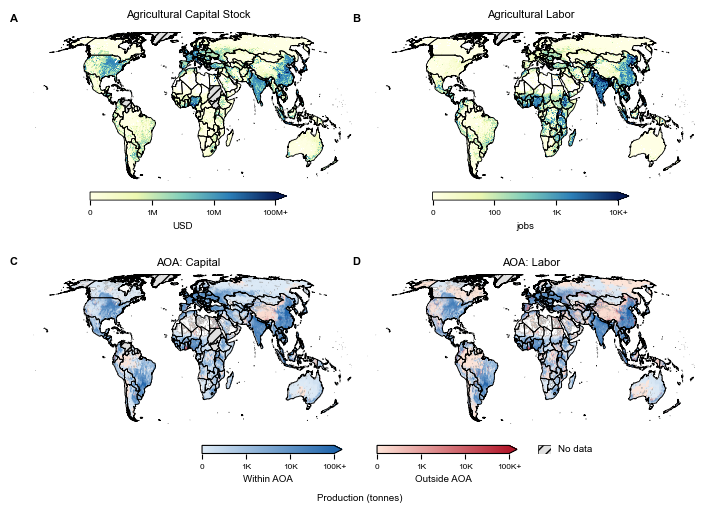

In [4]:
##### FIGURE 2: Capital, labor, and AOA

# set formatting
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['font.sans-serif'] = ['Arial', 'Helvetica']

TITLE_FS = 8   # panel titles
LABEL_FS = 7   # axis/colorbar labels
TICK_FS = 6    # tick labels
PANEL_LETTER_FS = 8

def draw_total_map(ax, value_plot, has_data_col, title, bounds):
    custom_cmap = mcolors.LinearSegmentedColormap.from_list(
        "white_ylgnbu",
        ["#ffffe5", "#edf8b1", "#7fcdbb", "#2c7fb8", "#081d58"]
    )
    custom_cmap.set_over("#081d58")
    custom_cmap.set_bad(color='none')

    country_boundaries[country_boundaries[has_data_col] == 0].plot(
        ax=ax, facecolor=no_data_color, edgecolor="none", hatch="////", zorder=1
    )
    country_boundaries.plot(ax=ax, facecolor="none", edgecolor="black", linewidth=0.6, zorder=2)

    positions = np.linspace(0, 1, len(bounds))
    def forward(x): return np.interp(x, bounds, positions)
    def inverse(x): return np.interp(x, positions, bounds)
    norm = mcolors.FuncNorm((forward, inverse), vmin=bounds[0], vmax=bounds[-1])

    im = value_plot.plot(ax=ax, cmap=custom_cmap, norm=norm,
                          add_colorbar=False, add_labels=False, zorder=0)
    ax.set_axis_off()
    ax.set_title(title, fontsize=TITLE_FS, pad=10)
    return im

def add_map_legend(fig, ax, im, bounds, labels, cbar_label):
    pos = ax.get_position()
    cbar_width = pos.width * 0.6
    cbar_x0 = pos.x0 + (pos.width - cbar_width) / 2
    cbar_y0 = pos.y0 - 0.035
    cbar_height = 0.015

    cax = fig.add_axes([cbar_x0, cbar_y0, cbar_width, cbar_height])
    cbar = fig.colorbar(im, cax=cax, orientation="horizontal", extend='max', extendfrac=0.06)
    cbar.set_label(cbar_label, fontsize=LABEL_FS, labelpad=4)
    cbar.ax.tick_params(labelsize=TICK_FS)
    cbar.set_ticks(bounds)
    cbar.set_ticklabels(labels)
    cbar.outline.set_linewidth(0.6)

within_cmap = mcolors.LinearSegmentedColormap.from_list("light_to_dark_blue", ["#deebf7", "#2166ac"])
outside_cmap = mcolors.LinearSegmentedColormap.from_list("light_to_dark_red", ["#fee5d9", "#b2182b"])

prod_bounds = [0, 1_000, 10_000, 100_000]
prod_labels = ['0', '1K', '10K', '100K+']
prod_positions = np.linspace(0, 1, len(prod_bounds))

def _prod_forward(x): return np.interp(x, prod_bounds, prod_positions)
def _prod_inverse(x): return np.interp(x, prod_positions, prod_bounds)
prod_norm = mcolors.FuncNorm((_prod_forward, _prod_inverse), vmin=prod_bounds[0], vmax=prod_bounds[-1])

def build_aoa_production_rgba(aoa_da, prod_da):
    aoa = aoa_da.values
    prod = np.clip(prod_da.values, prod_bounds[0], prod_bounds[-1])

    h, w = aoa.shape
    rgba = np.zeros((h, w, 4), dtype=float)

    valid = np.isfinite(aoa) & np.isfinite(prod)
    within = valid & (aoa == 1)
    outside = valid & (aoa == 0)

    rgba[within] = within_cmap(prod_norm(prod[within]))
    rgba[outside] = outside_cmap(prod_norm(prod[outside]))
    return rgba

capital_map_bounds = [0, 1_000_000, 10_000_000, 100_000_000]
capital_map_labels = ['0', '1M', '10M', '100M+']

labor_map_bounds = [0, 100, 1_000, 10_000]
labor_map_labels = ['0', '100', '1K', '10K+']

# ================= BUILD FIGURE =================
fig, axes = plt.subplots(2, 2, figsize=(7, 5.4), sharex=True, sharey=True)

im_capital_total = draw_total_map(axes[0, 0], capital_modeled, "has_capital_data",
                                    "Agricultural Capital Stock", capital_map_bounds)
im_labor_total = draw_total_map(axes[0, 1], labor_modeled, "has_labor_data",
                                  "Agricultural Labor", labor_map_bounds)

rgba_capital = build_aoa_production_rgba(aoa_plot_capital, prod_capital)
rgba_labor = build_aoa_production_rgba(aoa_plot_labor, prod_labor)

raster_left, raster_bottom, raster_right, raster_top = aoa_plot_capital.rio.bounds()

aoa_panels = [
    (rgba_capital, "has_capital_data", "AOA: Capital", axes[1, 0]),
    (rgba_labor,   "has_labor_data",   "AOA: Labor",   axes[1, 1]),
]

for rgba_img, data_flag_col, title, ax in aoa_panels:
    country_boundaries[country_boundaries[data_flag_col] == 0].plot(
        ax=ax, facecolor=no_data_color, edgecolor="none", hatch="///", zorder=1
    )
    country_boundaries.plot(ax=ax, facecolor="none", edgecolor="black", linewidth=0.6, zorder=2)
    ax.imshow(
        rgba_img,
        extent=[raster_left, raster_right, raster_bottom, raster_top],
        origin="upper",
        zorder=0,
    )
    ax.set_axis_off()
    ax.set_title(title, fontsize=TITLE_FS, pad=6)

axes[0, 0].set_xlim(minx, maxx)
axes[0, 0].set_ylim(miny, maxy)

plt.tight_layout()
fig.subplots_adjust(hspace=0.18, top=0.95, bottom=0.12)
fig.canvas.draw()

# ---- Panel labels ----
for ax, letter in zip(axes.flat, string.ascii_uppercase):
    ax.text(-0.02, 1.05, letter, transform=ax.transAxes,
            fontsize=PANEL_LETTER_FS, fontweight='bold', va='bottom', ha='right')

add_map_legend(fig, axes[0, 0], im_capital_total, bounds=capital_map_bounds, labels=capital_map_labels, cbar_label="USD")
add_map_legend(fig, axes[0, 1], im_labor_total, bounds=labor_map_bounds, labels=labor_map_labels, cbar_label="jobs")

sm_within = plt.cm.ScalarMappable(cmap=within_cmap, norm=prod_norm)
sm_outside = plt.cm.ScalarMappable(cmap=outside_cmap, norm=prod_norm)

row2_pos = axes[1, 0].get_position()
row2_right_pos = axes[1, 1].get_position()

cbar_y0 = row2_pos.y0 - 0.055
cbar_height = 0.015
cbar_width = 0.20

center_x = (row2_pos.x1 + row2_right_pos.x0) / 2
gap = 0.05
cbar_ax_within = fig.add_axes([center_x - cbar_width - gap / 2, cbar_y0, cbar_width, cbar_height])
cbar_ax_outside = fig.add_axes([center_x + gap / 2, cbar_y0, cbar_width, cbar_height])

cbar_within = fig.colorbar(sm_within, cax=cbar_ax_within, orientation="horizontal",
                            extend='max', extendfrac=0.06)
cbar_outside = fig.colorbar(sm_outside, cax=cbar_ax_outside, orientation="horizontal",
                             extend='max', extendfrac=0.06)

for cbar, label in [(cbar_within, "Within AOA"), (cbar_outside, "Outside AOA")]:
    cbar.set_ticks(prod_bounds)
    cbar.set_ticklabels(prod_labels)
    cbar.ax.tick_params(labelsize=TICK_FS)
    cbar.set_label(label, fontsize=LABEL_FS, labelpad=4)

fig.text(center_x, cbar_y0 - 0.075, "Production (tonnes)",
          fontsize=LABEL_FS, ha="center", va="top")

swatch_size = 0.018
legend_ax = fig.add_axes([center_x + cbar_width + gap / 2 + 0.03, cbar_y0, swatch_size, cbar_height])
legend_ax.add_patch(Rectangle(
    (0, 0), 1, 1, facecolor=no_data_color, edgecolor="black", linewidth=0.5, hatch="///"
))
legend_ax.set_xlim(0, 1); legend_ax.set_ylim(0, 1)
legend_ax.axis("off")
fig.text(center_x + cbar_width + gap / 2 + 0.03 + swatch_size + 0.01, cbar_y0 + cbar_height / 2,
          "No data", fontsize=LABEL_FS, va="center", ha="left")

plt.show()

fig.savefig(FIG_DIR / "Figure_2_capital_labor_AOA.tiff", dpi=300, bbox_inches='tight',
            facecolor='white')